# Single-Layer Perceptron for AND & OR Logic Gates

In this notebook, we design and implement a simple **Single-Layer Perceptron** from scratch using Python, NumPy, and Matplotlib.

### Objectives:
1. Understand the Perceptron architecture and Heaviside step activation.
2. Implement the Perceptron learning algorithm.
3. Train the Perceptron to model the **AND** and **OR** logic gates.
4. Evaluate the model predictions on all four possible input combinations.
5. Plot the 2D decision boundary showing clear linear separation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Display configuration
%matplotlib inline
np.random.seed(42)
print("NumPy and Matplotlib successfully imported.")

NumPy and Matplotlib successfully imported.


## 1. Perceptron Architecture & Learning Rule

A single perceptron computes a weighted sum of inputs plus a bias:
$$z = \mathbf{w} \cdot \mathbf{x} + b = w_1 x_1 + w_2 x_2 + b$$

The output is determined by the **Heaviside Step Function**:
$$\hat{y} = f(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

### Weight Update Rule:
For each training example $(\mathbf{x}, y)$:
$$\Delta w_i = \eta (y - \hat{y}) x_i$$
$$\Delta b = \eta (y - \hat{y})$$
$$w_i \leftarrow w_i + \Delta w_i, \quad b \leftarrow b + \Delta b$$



In [2]:
class Perceptron:
    def __init__(self, learning_rate=0.1, epochs=20):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0.0
        self.errors_per_epoch = []

    def activation(self, z):
        """Heaviside step activation function: 1 if z >= 0 else 0."""
        return np.where(z >= 0, 1, 0)

    def fit(self, X, y):
        """Train the perceptron on feature matrix X and target labels y."""
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.errors_per_epoch = []

        for epoch in range(1, self.epochs + 1):
            errors = 0
            for xi, target in zip(X, y):
                linear_output = np.dot(xi, self.weights) + self.bias
                # Round to avoid floating point precision issues near zero
                linear_output = round(float(linear_output), 6)
                y_pred = int(self.activation(linear_output))
                
                update = self.learning_rate * (target - y_pred)
                self.weights = np.round(self.weights + update * xi, 6)
                self.bias = round(self.bias + update, 6)
                
                if update != 0.0:
                    errors += 1
                    
            self.errors_per_epoch.append(errors)
            if errors == 0:
                print(f"Convergence achieved at epoch {epoch}!")
                break
        return self

    def predict(self, X):
        """Predict binary class labels for samples in X."""
        linear_output = np.dot(X, self.weights) + self.bias
        linear_output = np.round(linear_output, 6)
        return self.activation(linear_output)

print("Perceptron class defined successfully.")

Perceptron class defined successfully.


## 2. Dataset Definition: AND & OR Truth Tables

Truth tables for 2-input boolean logic gates:

| $x_1$ | $x_2$ | AND Target ($y$) | OR Target ($y$) |
|:---:|:---:|:---:|:---:|
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |


In [3]:
# Input dataset (all 4 binary input combinations)
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Ground truth outputs
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])

print("Inputs X:")
print(X)
print("\nTarget AND:", y_and)
print("Target OR: ", y_or)

Inputs X:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

Target AND: [0 0 0 1]
Target OR:  [0 1 1 1]


## 3. Evaluation and Visualization Helper Functions

The decision boundary occurs where $z = w_1 x_1 + w_2 x_2 + b = 0$.
Solving for $x_2$ in terms of $x_1$:
$$x_2 = -\frac{w_1 x_1 + b}{w_2}$$



In [4]:
def evaluate_model(model, X, y, gate_name="Logic Gate"):
    """Evaluates predictions across all input combinations and displays results."""
    preds = model.predict(X)
    correct_count = np.sum(preds == y)
    accuracy = (correct_count / len(y)) * 100
    
    print(f"=== {gate_name} Evaluation ===")
    print(f"Learned Weights: w1 = {model.weights[0]:.2f}, w2 = {model.weights[1]:.2f}")
    print(f"Learned Bias:    b  = {model.bias:.2f}")
    print("-" * 45)
    print(" x1 | x2 | Expected | Predicted | Status ")
    print("-" * 45)
    for (x1, x2), target, pred in zip(X, y, preds):
        status = "PASS (Correct)" if target == pred else "FAIL (Incorrect)"
        print(f"  {x1} |  {x2} |     {target}    |     {pred}     | {status}")
    print("-" * 45)
    print(f"Overall Accuracy: {accuracy:.1f}% ({correct_count}/{len(y)} correct)\n")
    return preds, accuracy

def plot_decision_boundary(model, X, y, title="Decision Boundary"):
    """Plots 2D data points and the perceptron's decision boundary."""
    fig, ax = plt.subplots(figsize=(6, 5))
    
    # Plot Class 0 and Class 1 points
    class_0 = X[y == 0]
    class_1 = X[y == 1]
    
    ax.scatter(class_0[:, 0], class_0[:, 1], color='#e74c3c', s=130, 
               marker='s', edgecolors='black', linewidth=1.5, label='Class 0 (Output = 0)', zorder=5)
    ax.scatter(class_1[:, 0], class_1[:, 1], color='#2ecc71', s=130, 
               marker='o', edgecolors='black', linewidth=1.5, label='Class 1 (Output = 1)', zorder=5)
    
    # Calculate decision boundary line: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b)/w2
    w1, w2 = model.weights
    b = model.bias
    x1_line = np.linspace(-0.2, 1.2, 100)
    
    if abs(w2) > 1e-6:
        x2_line = -(w1 * x1_line + b) / w2
        ax.plot(x1_line, x2_line, color='#2980b9', linestyle='--', linewidth=2,
                label=f'Boundary: {w1:.2f}$x_1$ + {w2:.2f}$x_2$ + {b:.2f} = 0')
    else:
        ax.axvline(x=-b / w1, color='#2980b9', linestyle='--', linewidth=2,
                   label=f'Boundary: $x_1$ = {-b/w1:.2f}')
        
    ax.set_xlim(-0.2, 1.2)
    ax.set_ylim(-0.2, 1.2)
    ax.set_xlabel('$x_1$ (Input 1)', fontsize=12)
    ax.set_ylabel('$x_2$ (Input 2)', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', framealpha=0.9)
    plt.tight_layout()
    plt.show()

print("Evaluation and plotting functions defined.")

Evaluation and plotting functions defined.


## 4. Training and Evaluating: AND Gate



Convergence achieved at epoch 6!
=== AND Gate Evaluation ===
Learned Weights: w1 = 0.20, w2 = 0.10
Learned Bias:    b  = -0.30
---------------------------------------------
 x1 | x2 | Expected | Predicted | Status 
---------------------------------------------
  0 |  0 |     0    |     0     | PASS (Correct)
  0 |  1 |     0    |     0     | PASS (Correct)
  1 |  0 |     0    |     0     | PASS (Correct)
  1 |  1 |     1    |     1     | PASS (Correct)
---------------------------------------------
Overall Accuracy: 100.0% (4/4 correct)



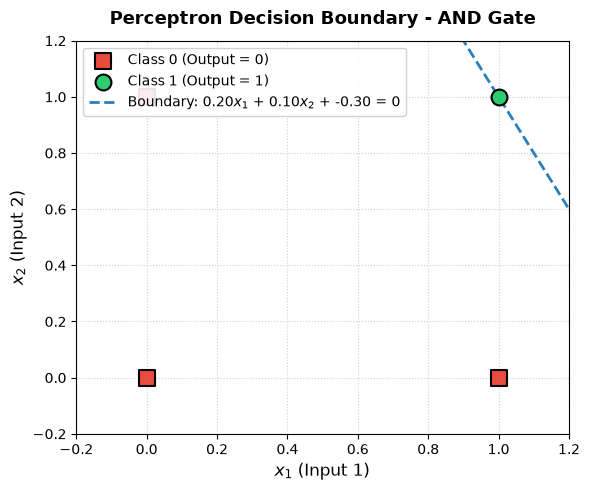

In [5]:
# 1. Initialize and train Perceptron for AND gate
p_and = Perceptron(learning_rate=0.1, epochs=20)
p_and.fit(X, y_and)

# 2. Evaluate predictions on all points
evaluate_model(p_and, X, y_and, gate_name="AND Gate")

# 3. Plot the decision boundary
plot_decision_boundary(p_and, X, y_and, title="Perceptron Decision Boundary - AND Gate")

## 5. Training and Evaluating: OR Gate



Convergence achieved at epoch 4!
=== OR Gate Evaluation ===
Learned Weights: w1 = 0.10, w2 = 0.10
Learned Bias:    b  = -0.10
---------------------------------------------
 x1 | x2 | Expected | Predicted | Status 
---------------------------------------------
  0 |  0 |     0    |     0     | PASS (Correct)
  0 |  1 |     1    |     1     | PASS (Correct)
  1 |  0 |     1    |     1     | PASS (Correct)
  1 |  1 |     1    |     1     | PASS (Correct)
---------------------------------------------
Overall Accuracy: 100.0% (4/4 correct)



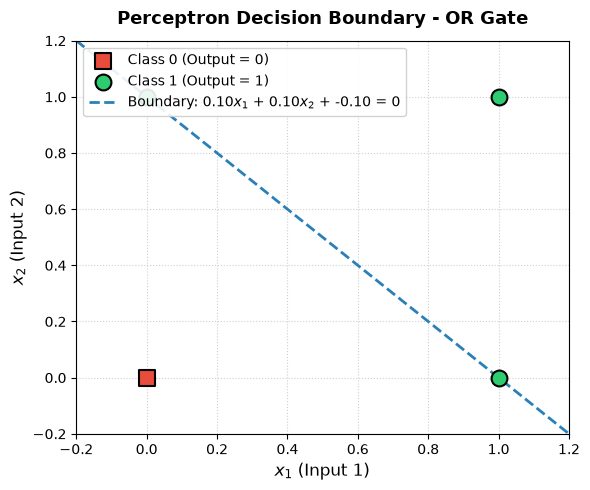

In [6]:
# 1. Initialize and train Perceptron for OR gate
p_or = Perceptron(learning_rate=0.1, epochs=20)
p_or.fit(X, y_or)

# 2. Evaluate predictions on all points
evaluate_model(p_or, X, y_or, gate_name="OR Gate")

# 3. Plot the decision boundary
plot_decision_boundary(p_or, X, y_or, title="Perceptron Decision Boundary - OR Gate")

## 6. Summary & Conclusion

- **Linear Separability**: Both the AND gate and OR gate are linearly separable boolean functions.
- **Convergence**: The Perceptron learning algorithm converged in a small number of epochs ($\le 6$ epochs) with zero training error.
- **Evaluation**: Both models achieved **100% classification accuracy** across all input combinations.
- **Decision Boundary**: The plotted linear boundary line clearly separates the Class 0 inputs from Class 1 inputs in 2D space.
